# Stage 6: Feature engineering
This is where most of the predictive power comes from. We turn ~58 million rows of credit history into one row of
behavioural features per applicant:

| Source | Feature family | Examples |
|---|---|---|
| Application | Affordability, stability, external scores | `ANNUITY_TO_INCOME_RATIO`, `YEARS_EMPLOYED`, `EXT_SOURCE_MEAN` |
| Bureau + bureau_balance | Credit history at other lenders | `BUREAU_CREDIT_HISTORY_YEARS`, `BUREAU_ACTIVE_DEBT_TO_CREDIT`, `BUREAU_BB_DPD_RATE_MEAN` |
| Previous applications | Relationship with Home Credit | `PREV_REFUSAL_RATE`, `PREV_RECENT_REFUSED`, `PREV_CREDIT_TO_APPLICATION_MEAN` |
| Instalments | **Payment delay** behaviour | `INST_LATE_RATE`, `INST_DAYS_LATE_MAX`, `INST_LATE_RATE_RECENT`, `INST_UNDERPAID_RATE` |
| POS / cash balances | Delinquency on past loans | `POS_DPD_RATE`, `POS_REMAINING_INSTALMENTS_SUM` |
| Credit card balances | **Credit utilisation** and minimum-payment behaviour | `CC_UTILIZATION_MEAN`, `CC_UTILIZATION_RECENT`, `CC_MISSED_MIN_RATE` |
| Cross-table | Total leverage, thin file | `TOTAL_DEBT_TO_INCOME`, `THIN_FILE` |

## Leakage prevention
Leakage means using information that wouldn't exist at the moment of the credit decision. It makes models look great
offline and fail in production. Our safeguards:
1. **Point-in-time filter:** only records dated before the application are used (`DAYS_* ≤ 0`, `MONTHS_BALANCE ≤ 0`).
2. **No target in features:** aggregations never touch `TARGET` (no target encoding on the full data).
3. **Per-client aggregation only:** each client's features depend only on their own history, so computing them before
   the train/test split leaks nothing between clients.
4. **Learned transforms fitted on train only** (imputation, scaling, encoding, feature selection: Stage 7).
5. **Audit:** any single feature with a suspiciously high univariate AUC is flagged for review (below).

In [1]:
import sys
import time
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from credit_risk.config import get_paths, load_config
from credit_risk.data_loader import load_table
from credit_risk.features import AGG_PREFIXES, assemble_features, build_aggregated_features
from credit_risk.viz import COLORS, savefig, set_style

cfg = load_config()
paths = get_paths(cfg)
set_style()

## 1. Load the cleaned applications and raw history tables

In [2]:
app_train = pd.read_parquet(paths["interim_data"] / "application_train_clean.parquet")
app_test = pd.read_parquet(paths["interim_data"] / "application_test_clean.parquet")

history_keys = ["bureau", "bureau_balance", "previous_application", "pos_cash_balance", "installments_payments", "credit_card_balance"]
tables = {}
for k in history_keys:
    tables[k] = load_table(k, cfg)
    print(f"{k:<24} {len(tables[k]):>12,} rows")

bureau                      1,716,428 rows
bureau_balance             27,299,925 rows
previous_application        1,670,214 rows
pos_cash_balance           10,001,358 rows
installments_payments      13,605,401 rows
credit_card_balance         3,840,312 rows


### Point-in-time audit
How many history records are dated *after* the application? These would be future information.

In [3]:
time_cols = {
    "bureau": ["DAYS_CREDIT", "DAYS_ENDDATE_FACT", "DAYS_CREDIT_UPDATE"],
    "previous_application": ["DAYS_DECISION"],
    "installments_payments": ["DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT"],
    "bureau_balance": ["MONTHS_BALANCE"],
    "pos_cash_balance": ["MONTHS_BALANCE"],
    "credit_card_balance": ["MONTHS_BALANCE"],
}
audit = [{"table": t, "column": c, "records_after_application": int((tables[t][c] > 0).sum())} for t, cols in time_cols.items() for c in cols]
pd.DataFrame(audit)

,table,column,records_after_application
0,bureau,DAYS_CREDIT,0
1,bureau,DAYS_ENDDATE_FACT,0
2,bureau,DAYS_CREDIT_UPDATE,17
3,previous_application,DAYS_DECISION,0
4,installments_payments,DAYS_INSTALMENT,0
5,installments_payments,DAYS_ENTRY_PAYMENT,0
6,bureau_balance,MONTHS_BALANCE,0
7,pos_cash_balance,MONTHS_BALANCE,0
8,credit_card_balance,MONTHS_BALANCE,0


Home Credit already provides history *before* the application, so these counts should be zero or close to it. The cleaning
functions drop any that exist anyway. **Note:** `DAYS_CREDIT_ENDDATE > 0` (a *planned* end date in the future) is
legitimate: it is known at decision time.

## 2. Build historical aggregates (one row per client)

In [4]:
start = time.time()
aggregated = build_aggregated_features(tables)
print(f"\nAggregated features: {aggregated.shape[1] - 1} columns for {len(aggregated):,} clients in {time.time() - start:.0f}s")
assert "TARGET" not in aggregated.columns, "Leakage: TARGET must never enter the aggregates"
aggregated.to_parquet(paths["processed_data"] / "aggregated_features.parquet", index=False)
del tables

  bureau                   ->  40 features for   305,811 clients
  previous_application     ->  21 features for   338,857 clients
  installments_payments    ->  14 features for   339,587 clients
  pos_cash_balance         ->  11 features for   337,252 clients
  credit_card_balance      ->  13 features for   103,558 clients

Aggregated features: 99 columns for 353,895 clients in 53s


## 3. Assemble the modelling tables
`assemble_features()` is the single function used by both training and the Streamlit app, so the scoring
features are guaranteed to match the training features.

In [5]:
features_train = assemble_features(app_train, aggregated)
features_test = assemble_features(app_test, aggregated)
assert len(features_train) == len(app_train) and features_train["SK_ID_CURR"].is_unique
assert set(features_train.columns) - {"TARGET"} == set(features_test.columns), "train/test feature mismatch"
print(f"Train features: {features_train.shape} | Kaggle test features: {features_test.shape}")

Train features: (307511, 244) | Kaggle test features: (48744, 243)


## 4. Feature catalogue

In [6]:
source_map = {"BUREAU_": "bureau + bureau_balance", "PREV_": "previous_application", "INST_": "installments_payments",
              "POS_": "POS_CASH_balance", "CC_": "credit_card_balance"}
engineered_app = [c for c in features_train.columns if c not in app_train.columns and not c.startswith(AGG_PREFIXES)]
catalogue = pd.DataFrame(
    [{"feature": c, "source": next((v for k, v in source_map.items() if c.startswith(k)), "application (engineered)" if c in engineered_app else "application (raw)"),
      "missing_pct": round(100 * features_train[c].isna().mean(), 1)} for c in features_train.columns if c not in ("SK_ID_CURR", "TARGET")]
)
display(catalogue.groupby("source").agg(n_features=("feature", "size"), avg_missing_pct=("missing_pct", "mean")).round(1))
catalogue.to_csv(paths["reports"] / "feature_catalogue.csv", index=False)

,n_features,avg_missing_pct
source,,
POS_CASH_balance,11,5.4
application (engineered),26,6.6
application (raw),116,25.7
bureau + bureau_balance,41,28.1
credit_card_balance,13,68.1
installments_payments,14,8.3
previous_application,21,8.7


## 5. Do the engineered features carry signal?
Univariate ROC-AUC of each feature (direction-free: `max(AUC, 1 - AUC)`). This is a quick screen, not feature selection.

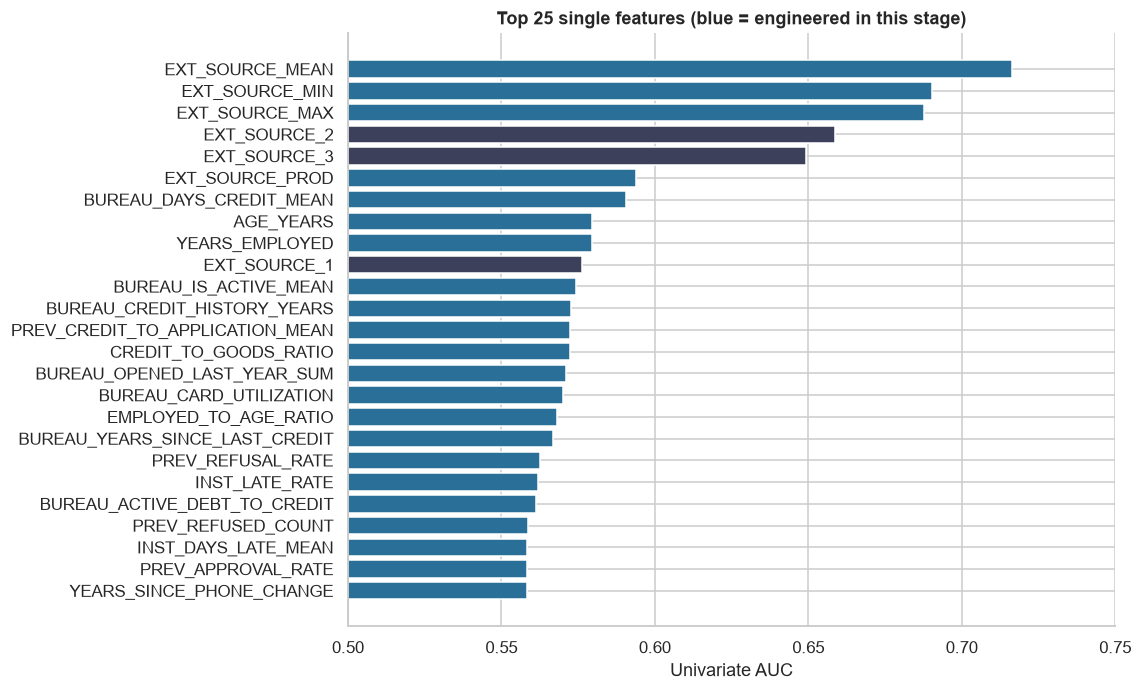

22 of the top 25 features are engineered.


In [7]:
sample = features_train.sample(min(len(features_train), 100_000), random_state=0)
y = sample["TARGET"]
rows = []
for c in sample.columns:
    if c in ("SK_ID_CURR", "TARGET") or not pd.api.types.is_numeric_dtype(sample[c]):
        continue
    x = sample[c]
    if x.nunique() < 2:
        continue
    auc = roc_auc_score(y, x.fillna(x.median()))
    rows.append({"feature": c, "univariate_auc": max(auc, 1 - auc), "engineered": c not in app_train.columns})
uni = pd.DataFrame(rows).sort_values("univariate_auc", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 7))
top = uni.head(25)[::-1]
ax.barh(top["feature"], top["univariate_auc"], color=np.where(top["engineered"], COLORS["good"], COLORS["neutral"]))
ax.axvline(0.5, color="grey", lw=1)
ax.set(xlim=(0.5, max(0.75, top["univariate_auc"].max() + 0.02)), xlabel="Univariate AUC",
       title="Top 25 single features (blue = engineered in this stage)")
savefig(fig, "features_univariate_auc")
plt.show()
print(f"{uni.head(25)['engineered'].sum()} of the top 25 features are engineered.")

### Leakage red-flag check
A single feature with AUC > 0.80 in credit scoring is almost always leakage (for example, a field filled in *after*
the loan went bad). On the full Home Credit data the best single feature (`EXT_SOURCE_MEAN`) sits around 0.7.

In [8]:
suspicious = uni[uni["univariate_auc"] > 0.80]
print("Suspicious features:", suspicious["feature"].tolist() or "none ✓")

Suspicious features: none ✓


## 6. Example: payment-delay feature vs default rate

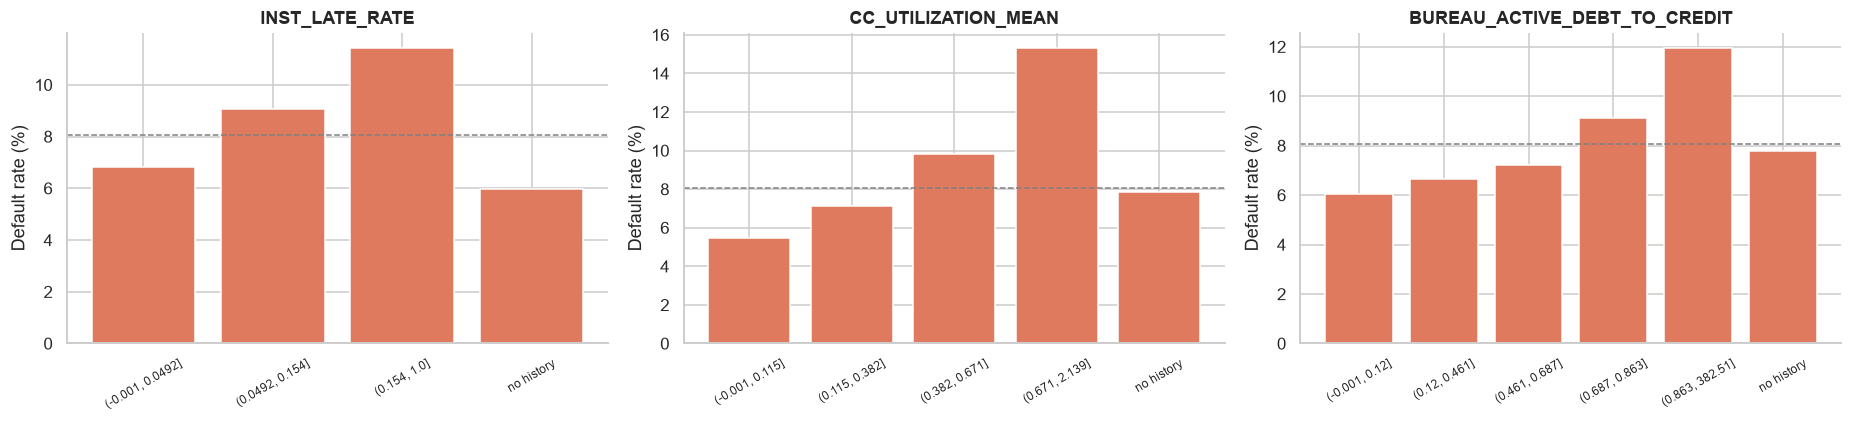

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["INST_LATE_RATE", "CC_UTILIZATION_MEAN", "BUREAU_ACTIVE_DEBT_TO_CREDIT"]):
    s = features_train[[col, "TARGET"]].copy()
    s["bucket"] = pd.qcut(s[col], 5, duplicates="drop").astype(str)
    s.loc[s[col].isna(), "bucket"] = "no history"
    r = s.groupby("bucket", observed=True)["TARGET"].agg(["mean", "size"])
    ax.bar(r.index, 100 * r["mean"], color=COLORS["bad"])
    ax.axhline(100 * features_train["TARGET"].mean(), ls="--", color="grey", lw=1)
    ax.set(title=col, ylabel="Default rate (%)")
    ax.tick_params(axis="x", rotation=30, labelsize=8)
fig.tight_layout()
savefig(fig, "features_behaviour_signal")
plt.show()

## 7. Save

In [10]:
features_train.to_parquet(paths["processed_data"] / "features_train.parquet", index=False)
features_test.to_parquet(paths["processed_data"] / "features_test.parquet", index=False)
uni.to_csv(paths["reports"] / "univariate_auc.csv", index=False)
print("Saved features_train / features_test / aggregated_features to data/processed/")

Saved features_train / features_test / aggregated_features to data/processed/
